# Figures 3 and 4 — Statistical asymmetry of elementary cellular automata

Each rule evolves the same 100-cell initial state shown in Figure 2,
generated with NumPy's `RandomState(55)`. Each simulation records
20,000 states, including the initial state at index 0.

Each panel shows the last 200 states and their statistical asymmetry
under translations and reflection. Figure 4(b) uses Rule 3, as shown
in the published panel title and Table 2. The published caption says
Rule 2.

In [1]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import entropy

In [2]:
def hamming(x, y):
    return np.count_nonzero(x!=y)   

def translations(array):
    x = np.asarray(array)
    m = len(x)//2 + 1
    k = np.zeros(m)
    
    for i in range(m):
        ss = np.roll(x, i)
        k[i] = hamming(x, ss)

    return k, m

def reflections(array):
    x = np.asarray(array)
    y = x[::-1]
    
    return np.asarray([0, hamming(x,y)]), 2

def disc_dist(sequence):
    
    d = set(sequence)
    m = len(d)
    
    pk = np.zeros(m)
    for i in range(m):
        pk[i] = list(sequence).count(list(d)[i])
    
    return pk/sum(pk)
    
# Scaled by maximum distance
def sA(x, group):
    s = group(x)
    d1 = s[0]
    p1 = disc_dist(d1)
    n1 = s[1]
    e1 = entropy(p1)/np.log(n1)
    
    return e1*np.max(d1)/len(x.flatten())

In [3]:
def rule_index(triplet):
    L, C, R = triplet
    index = 7 - (4*L + 2*C + R)
    return int(index)

def CA_run(initial_state, n_steps, rule_number):
    rule_string = np.binary_repr(rule_number, 8)
    rule = np.array([int(bit) for bit in rule_string])

    m_cells = len(initial_state)
    CA_run = np.zeros((n_steps, m_cells))
    CA_run[0, :] = initial_state

    for step in range(1, n_steps):
        all_triplets = np.stack(
            [
                np.roll(CA_run[step - 1, :], 1),
                CA_run[step - 1, :],
                np.roll(CA_run[step - 1, :], -1),
            ]
        )
        CA_run[step, :] = rule[np.apply_along_axis(rule_index, 0, all_triplets)]

    return CA_run

def CA_complexity(initial_state, time_steps, rule, group):
    config = CA_run(initial_state, time_steps, rule)
    c = []
    for s in config:
        c += [sA(s, group)]
    
    return c

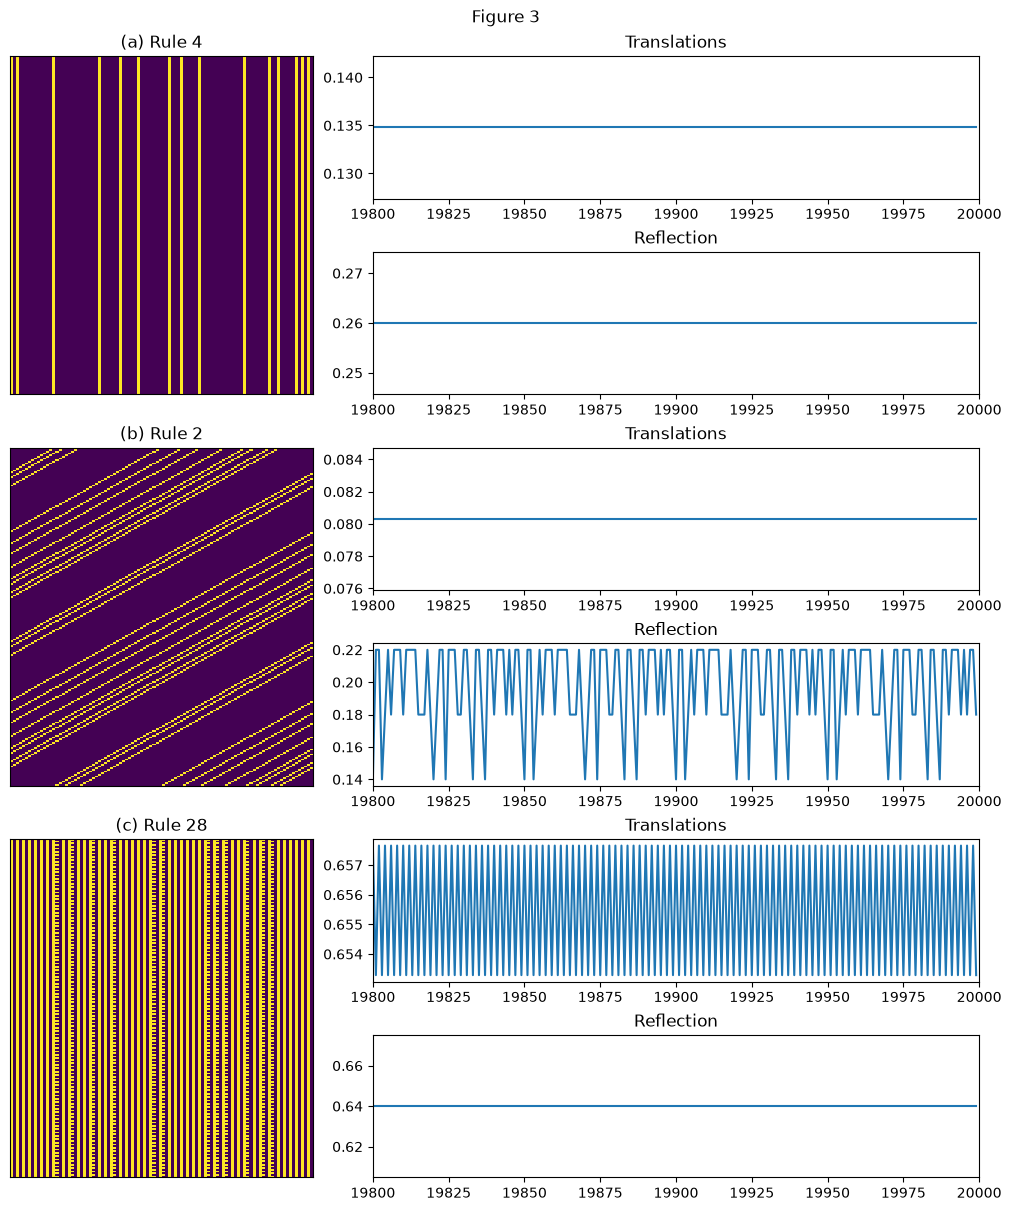

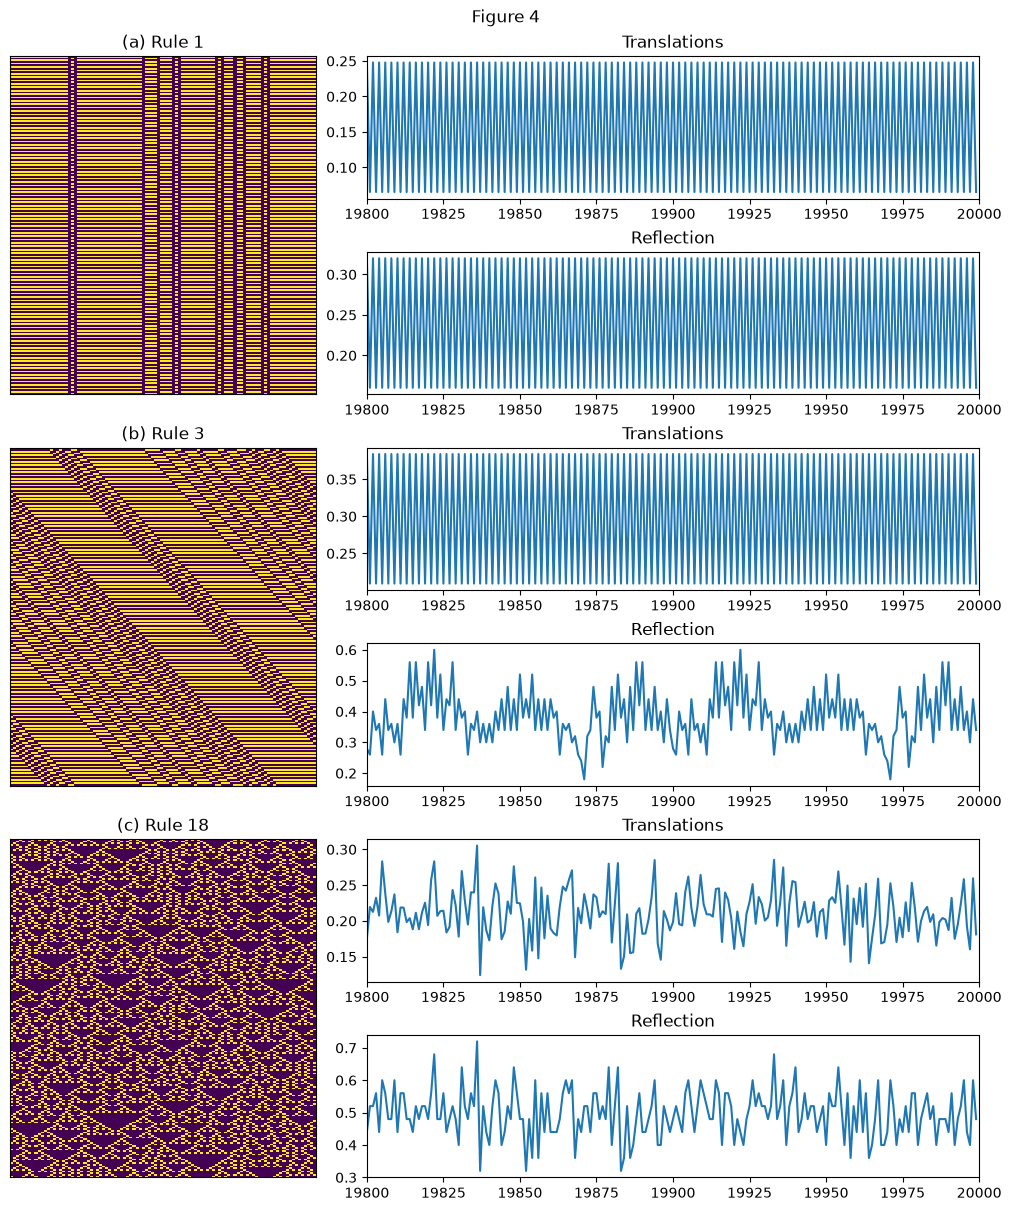

In [4]:
initial_state = np.random.RandomState(55).randint(0, 2, 100)
total_states = 20_000
window_start = 19_800
time = np.arange(window_start, total_states)

for figure_number, rules in ((3, (4, 2, 28)), (4, (1, 3, 18))):
    fig = plt.figure(figsize=(10, 12), layout="constrained")
    fig.suptitle(f"Figure {figure_number}")
    layout = fig.add_gridspec(6, 2, width_ratios=(1, 2))

    for row, rule in enumerate(rules):
        trajectory = CA_run(initial_state, total_states, rule)[window_start:]
        panel = "abc"[row]

        ax_states = fig.add_subplot(layout[2 * row:2 * row + 2, 0])
        ax_states.imshow(
            trajectory, cmap="viridis", aspect="auto",
            interpolation="nearest", vmin=0, vmax=1,
        )
        ax_states.set_title(f"({panel}) Rule {rule}")
        ax_states.set_xticks([])
        ax_states.set_yticks([])

        for offset, (title, transform) in enumerate(
            (("Translations", translations), ("Reflection", reflections))
        ):
            ax = fig.add_subplot(layout[2 * row + offset, 1])
            ax.plot(time, [sA(state, transform) for state in trajectory])
            ax.set_title(title)
            ax.set_xlim(window_start, total_states)

    plt.show()